# 📘 Árboles de Decisión: Gini, Entropía y Métricas de Evaluación

In [1]:

import numpy as np
import random
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns


### Árboles de Decisión: Conceptos Clave

En este notebook vamos a repasar las fórmulas y métricas más utilizadas
cuando trabajamos con **árboles de decisión**:

- Índice Gini
- Entropía
- Accuracy
- Matriz de Confusión
- Definiciones de Ciertos Positivos, Negativos y errores


In [2]:
# ===============================
# 2. Crear un dataset sencillo
# ===============================
# Dataset ficticio: "Clima" para decidir si salir a jugar
def generar_fila_aleatoria():
    opciones_clima = ["Soleado", "Nublado", "Lluvioso"]
    opciones_humedad = ["Alta", "Normal"]
    
    clima = random.choice(opciones_clima)
    humedad = random.choice(opciones_humedad)
    
    # Aplicar las reglas del dataset original
    if clima == "Soleado":
        jugar = "No" if humedad == "Alta" else random.choice(["Sí", "No"])
    elif clima == "Nublado":
        jugar = "Sí"
    elif clima == "Lluvioso":
        jugar = "Sí" if humedad == "Normal" else random.choice(["Sí", "No"])
    
    return [clima, humedad, jugar]

nuevas_filas = [generar_fila_aleatoria() for _ in range(100)]
df = pd.DataFrame(nuevas_filas, columns=["Clima", "Humedad", "Jugar"])
df


,Clima,Humedad,Jugar
0,Soleado,Normal,Sí
1,Lluvioso,Alta,Sí
2,Nublado,Alta,Sí
3,Soleado,Alta,No
4,Lluvioso,Alta,Sí
...,...,...,...
95,Soleado,Normal,Sí
96,Lluvioso,Normal,Sí
97,Lluvioso,Alta,Sí
98,Nublado,Normal,Sí


### Dataset de ejemplo

Este dataset contiene 10 instancias con dos atributos (**Clima** y **Humedad**) 
y la variable objetivo **Jugar** (Sí/No).

***One-Hot Encoding: Es una técnica de preprocesamiento de datos categóricos que convierte variables de tipo texto/categoría en variables numéricas binarias (0 y 1), para que los algoritmos de machine learning puedan entenderlas.***

`pd.get_dummies`

Es una función de pandas que aplica One-Hot Encoding automáticamente sobre columnas categóricas.
Convierte valores de texto o categorías en columnas binarias (0/1).

* pd → el DataFrame original.
* columns  → lista de columnas a transformar (si no se especifica, aplica a todas las categóricas).
* drop_first=True → elimina la primera categoría de cada variable (para evitar multicolinealidad en modelos lineales).
* prefix → prefijo para las nuevas columnas.

In [3]:
# ===============================
# 3. Preprocesamiento (One-Hot Encoding)
# ===============================
X = pd.get_dummies(df[["Clima", "Humedad"]], drop_first=True)
X

,Clima_Nublado,Clima_Soleado,Humedad_Normal
0,False,True,True
1,False,False,False
2,True,False,False
3,False,True,False
4,False,False,False
...,...,...,...
95,False,True,True
96,False,False,True
97,False,False,False
98,True,False,True


* Clima tiene 3 categorías → Soleado, Nublado, Lluvioso.
* Humedad tiene 2 categorías → Alta, Normal.

***Nota: Se generaron 2 columnas (Nublado, Soleado), y no aparece Lluvioso porque lo eliminó para evitar multicolinealidad (dummy variable trap).***

In [4]:
y = df["Jugar"].map({"No": 0, "Sí": 1})  # Codificar la variable objetivo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Índice Gini (Nodo Binario)

La fórmula del **Índice Gini** para un nodo binario es:

$$
\text{Índice Gini} = 1 - (P(\text{Clase 1}))^2 - (P(\text{Clase 2}))^2
$$

- Si todas las instancias pertenecen a la misma clase → Gini = 0 (nodo puro).
- Si están balanceadas 50%-50% → Gini = 0.5 (impureza máxima).


In [5]:
# ===============================
# 4. Funciones para calcular Gini y Entropía
# ===============================
def gini(p):
    return 1 - np.sum(p**2)

def entropy(p):
    return -np.sum([pi * np.log2(pi) for pi in p if pi > 0])

# Ejemplo: Nodo con 4 instancias [3 de Clase 1, 1 de Clase 0]
p = np.array([3/4, 1/4])
print("Distribución:", p)
print("Índice Gini:", gini(p))
print("Entropía:", entropy(p))

Distribución: [0.75 0.25]
Índice Gini: 0.375
Entropía: 0.8112781244591328


### 🔍 Interpretación

- Con 75% de una clase y 25% de otra:
  - **Índice Gini** ≈ 0.375
  - **Entropía** ≈ 0.81

Ambos valores indican que el nodo está "mezclado", pero no tanto como si fuera 50%-50%.


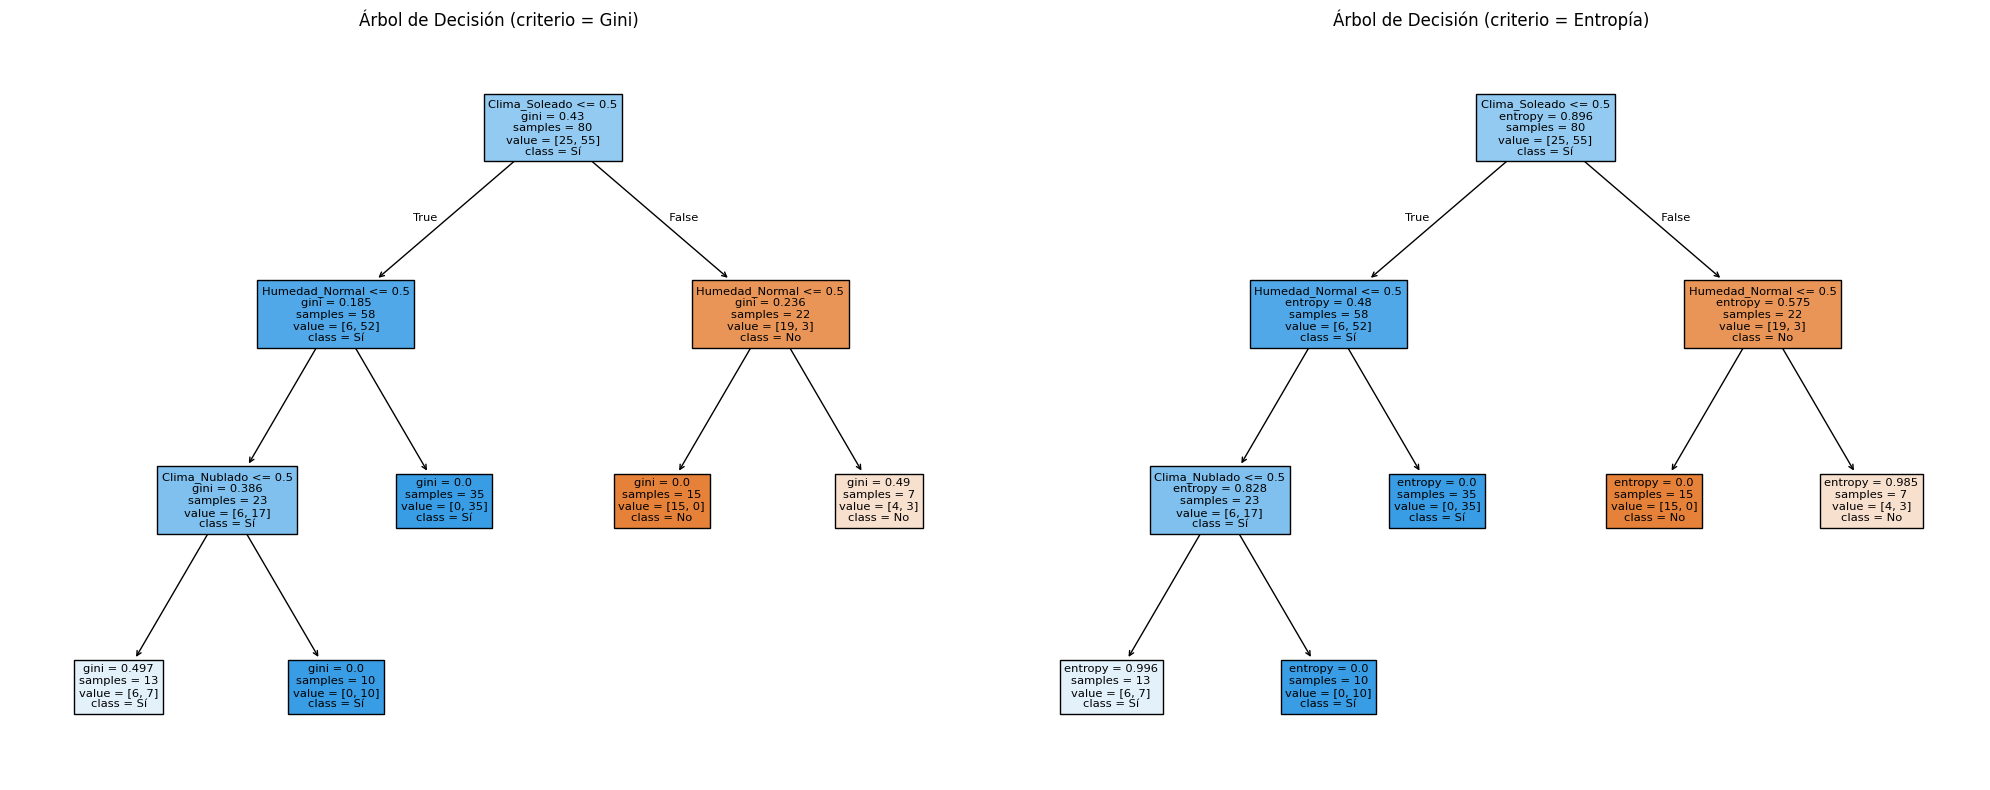

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# ===============================
# 5. Entrenar Árbol de Decisión (criterio Gini y Entropía)
# ===============================
clf_gini = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini.fit(X_train, y_train)

clf_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_entropy.fit(X_train, y_train)

# ===============================
# Visualizar ambos árboles en una sola figura
# ===============================
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Árbol Gini
plot_tree(clf_gini,  feature_names=X.columns, class_names=["No", "Sí"],  filled=True,  ax=axes[0])
axes[0].set_title("Árbol de Decisión (criterio = Gini)")

# Árbol Entropía
plot_tree(clf_entropy, feature_names=X.columns,  class_names=["No", "Sí"],  filled=True,  ax=axes[1])
axes[1].set_title("Árbol de Decisión (criterio = Entropía)")

plt.tight_layout()
plt.show()


### Accuracy y Matriz de Confusión

La fórmula de la **Accuracy** es:

$$
\text{Accuracy} = \frac{\text{Ciertos Positivos} + \text{Ciertos Negativos}}{\text{Total de predicciones}}
$$


Accuracy: 0.7

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.43      0.60      0.50         5
           1       0.85      0.73      0.79        15

    accuracy                           0.70        20
   macro avg       0.64      0.67      0.64        20
weighted avg       0.74      0.70      0.71        20



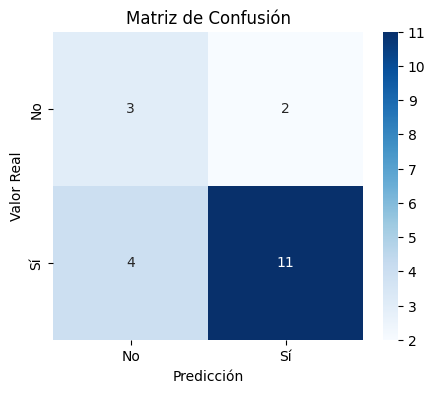

In [7]:
# ===============================
# 6. Evaluar modelo con Gini
# ===============================
y_pred = clf_gini.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Accuracy:", acc)
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))

# Matriz de confusión
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No", "Sí"], yticklabels=["No", "Sí"])
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.title("Matriz de Confusión")
plt.show()



***80% de las predicciones totales fueron correctas***

### Clase 0

* **Precisión = 0.64** → de todos los predichos como "0", solo el 64% eran realmente 0.
* **Recall = 1.00** → de todos los verdaderos "0", el modelo reconoció el 100%.
* **F1-score = 0.78** → buen balance, aunque la precisión es baja.

### Clase 1

* **Precisión = 1.00** → de todos los predichos como "1", el 100% eran realmente 1.
* **Recall = 0.69** → de todos los verdaderos "1", el modelo reconoció solo el 69%.
* **F1-score = 0.82** → sólido, pero limitado por el bajo recall.


In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# ======================
# 1. Cargar dataset
# ======================
df = pd.read_csv("calima_windguru_limpio.csv")

# Limpiar columnas numéricas
df["WINDSPD"] = pd.to_numeric(df["WINDSPD"], errors="coerce")
df["GUST"] = pd.to_numeric(df["GUST"], errors="coerce")
df["TMPE"] = pd.to_numeric(df["TMPE"], errors="coerce")
df["APCP1s"] = pd.to_numeric(df["APCP1s"], errors="coerce")

# Nubosidad (CDC) → tomar el promedio si hay varios valores
def parse_cdc(val):
    if pd.isna(val):
        return np.nan
    try:
        nums = [int(x) for x in str(val).split() if x.isdigit()]
        return np.mean(nums) if nums else np.nan
    except:
        return np.nan

df["CDC"] = df["CDC"].apply(parse_cdc)

# ======================
# 2. Crear etiqueta Navegable
# ======================
df["Navegable"] = np.where(
    (df["WINDSPD"] >= 10) & 
    (df["WINDSPD"] <= 25) & 
    (df["APCP1s"].fillna(0) < 2), 1, 0
)

print(df)
# ======================
# 3. Features & Target
# ======================
X = df[["WINDSPD", "GUST", "TMPE", "CDC", "APCP1s"]].fillna(0)
y = df["Navegable"]

# ======================
# 4. Entrenar Árbol
# ======================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# ======================
# 5. Evaluación
# ======================
print("Accuracy:", clf.score(X_test, y_test))

# ======================
# 6. Visualizar Árbol
# ======================
plt.figure(figsize=(14,7))
plot_tree(clf, feature_names=X.columns, class_names=["No", "Sí"], filled=True)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'calima_windguru_limpio.csv'